# Import right dependencies

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from keras.datasets import mnist
from sklearn.metrics import classification_report, confusion_matrix

# Import dataset

In [2]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()
print(train_X.shape)
print(train_y.shape)

(60000, 28, 28)
(60000,)


# One hot encode train and test labels

In [3]:
train_y_one_hot= to_categorical(train_y)
train_y_one_hot = np.einsum('vz->zv', train_y_one_hot)
test_y_one_hot= to_categorical(test_y)
test_y_one_hot = np.einsum('vz->zv', test_y_one_hot)
print(train_X.shape)
print(train_y_one_hot.shape)

(60000, 28, 28)
(10, 60000)


# Flatten and reshape train and test inputs

In [4]:
train_x_flatten = train_X.reshape(train_X.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_X.reshape(test_X.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))

train_x's shape: (784, 60000)
test_x's shape: (784, 10000)


# Define neural network architecture

In [5]:
#input dymension, hidden_layers
layers_dims = [784, 30, 20, 15, 10]

# Define activation functions

In [6]:
def relu(z):
    A = np.maximum(0, z)
    cache = z 
    return A, cache

In [7]:
def sigmoid(z):
    s = 1 / (1 + np.exp(-z))
    cache = z
    return s, cache

In [8]:
def softmax(z):
    cache = z 
    z_norm = z - np.max(z, axis=0, keepdims=True)   # max per column (per image), so no probability rounds to 0
    exp = np.exp(z_norm)
    exp = exp / np.sum(exp, axis=0, keepdims=True)
    return exp, cache

# Define forward propagation functions

In [9]:
def initialize_parameters_deep(layer_dims):
    np.random.seed(1)
    parameters = {}
    L = len(layer_dims)            # number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) / np.sqrt(layer_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

In [10]:
def linear_forward(A, W, b):
    Z = W @ A + b
    cache = (A, W, b)
    return Z, cache

In [11]:
def linear_activation_forward(A_prev, W, b, activation):
    # same linear step for every layer, only the squashing function changes
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "softmax":
        A, activation_cache = softmax(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    cache = (linear_cache, activation_cache)

    return A, cache

# Define model forward function

In [12]:
def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2            

    for l in range(1, L):
        A_prev = A 
        A, cache = linear_activation_forward(A_prev, parameters['W' + str(l)], parameters['b' + str(l)], "relu")
        caches.append(cache)
    
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], "softmax")
    caches.append(cache)
    
    return AL, caches

# Define cost functions

In [13]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = -np.mean(Y * np.log(AL))
    cost = np.squeeze(cost)
    return cost

# Define activation function derivatives with respect to loss

In [14]:
def sigmoid_backward(dA, cache):
    Z = cache 
    s, _ = sigmoid(Z)
    dZ = dA * s * (1-s)
    return dZ

In [15]:
def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True) 
    dZ[Z <= 0] = 0
    return dZ

# Define backward propagation functions

In [16]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = np.multiply(1/m,np.dot(dZ, A_prev.transpose()))
    db = np.multiply(1/m,np.sum(dZ, axis = 1, keepdims = True))
    dA_prev = np.dot(W.transpose(),dZ)

    return dA_prev, dW, db

In [17]:
def linear_activation_backward(dA, cache, activation):

    linear_cache, activation_cache = cache
    
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    elif activation == "softmax":
        dZ = dA   # softmax + cross-entropy: dA passed in is already AL - Y = dZ

    dA_prev, dW, db = linear_backward(dZ, linear_cache)
    return dA_prev, dW, db

# Define model backward function

In [18]:
def L_model_backward(AL, Y, caches):

    grads = {}
    L = len(caches) # the number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    
    dAL = (AL - Y)
    
    current_cache = caches[L-1]
    dA_prev_temp, dW_temp, db_temp = linear_activation_backward(dAL, current_cache, "softmax")
    grads["dA" + str(L-1)] = dA_prev_temp
    grads["dW" + str(L)] = dW_temp
    grads["db" + str(L)] = db_temp
    
    for l in reversed(range(L-1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l+1)], current_cache, "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l+1)] = dW_temp
        grads["db" + str(l+1)] = db_temp

    return grads

In [19]:
def update_parameters(params, grads, learning_rate):
    parameters = params.copy()
    L = len(parameters) // 2 
    for l in range(1, L + 1):
        parameters["W" + str(l)] = params["W" + str(l)] - learning_rate * grads["dW" + str(l)]
        parameters["b" + str(l)] = params["b" + str(l)] - learning_rate * grads["db" + str(l)]

    return parameters

# Define model

In [20]:
def L_layer_model(X, Y, layers_dims, learning_rate = 0.9, num_iterations = 3000, print_cost=False):

    np.random.seed(1)
    costs = []                         # keep track of cost
    parameters = initialize_parameters_deep(layers_dims)

    for i in range(0, num_iterations):
        AL, caches = L_model_forward(X, parameters)
        cost = compute_cost(AL, Y)
        grads = L_model_backward(AL, Y, caches)
        parameters = update_parameters(parameters, grads, learning_rate)
                
        # Print the cost every 100 iterations
        if print_cost and i % 100 == 0 or i == num_iterations - 1:
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if i % 100 == 0 or i == num_iterations:
            costs.append(cost)
    
    return parameters, costs

# Train model

In [21]:
parameters, costs = L_layer_model(train_x, train_y_one_hot, layers_dims, num_iterations=3000, print_cost=True)

Cost after iteration 0: 0.23168352039847223


Cost after iteration 100: 0.0634434065364493


Cost after iteration 200: 0.032278347511549045


Cost after iteration 300: 0.03408615754780325


Cost after iteration 400: 0.03698276266821572


Cost after iteration 500: 0.018686622869346484


... (21 outputs left out)

Cost after iteration 2700: 0.018030950020880267


Cost after iteration 2800: 0.09227734944815466


Cost after iteration 2900: 0.0727202570024451


Cost after iteration 2999: 0.06543613168204676


# Define function for predictions and their accuracy

In [22]:
def predict(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    return np.argmax(probas, axis=0)    

In [23]:
def accuracy(y, y_hat):
    acc = np.sum(y==y_hat)/len(y)
    return acc

# Make predictions on training data, get accuracy

In [24]:
pred_train = predict(train_x, train_y, parameters)

In [25]:
accuracy(train_y, pred_train)

np.float64(0.791)

# Print confusion matrix and classification report for train predictions

In [26]:
print(confusion_matrix(train_y, pred_train))
print(classification_report(train_y, pred_train))

[[5611    6  146   24    7   61   42    0   18    8]
 [  15 6497   60   25    6   40   13    5   74    7]
 [ 791   23 4258   30   90   12  341   11  275  127]
 [ 163   49  211 3349    2  409   23   27 1787  111]
 [   9   11   39    0 5265   13  169   22   11  303]
 [ 215  117   47  621   11 4236  100   48   22    4]
 [ 199   25  123   17   76   42 5419    0    9    8]
 [  17   29   58   13   78   32   10 4849   87 1092]
 [  35  197  239  658   22   48   62   14 4497   79]
 [  29   23   51  123  185   20   13 1958   68 3479]]
              precision    recall  f1-score   support

           0       0.79      0.95      0.86      5923
           1       0.93      0.96      0.95      6742
           2       0.81      0.71      0.76      5958
           3       0.69      0.55      0.61      6131
           4       0.92      0.90      0.91      5842
           5       0.86      0.78      0.82      5421
           6       0.88      0.92      0.89      5918
           7       0.70      0.77   

# Make predictions on test data, get accuracy

In [27]:
pred_test = predict(test_x, test_y, parameters)
accuracy(test_y, pred_test)

np.float64(0.7939)

# Print confusion matrix and classification report for test predictions

In [28]:
print(confusion_matrix(test_y, pred_test))
print(classification_report(test_y, pred_test))

[[ 941    0   13    3    1    8   11    1    2    0]
 [   1 1102    7    5    2    1    4    1   12    0]
 [ 118    2  763    4   16    2   44    2   59   22]
 [  31    4   40  554    0  103    4    6  249   19]
 [   1    0    7    0  888    3   26    7    4   46]
 [  29   15   12   83    2  715   13    9   11    3]
 [  44    2   18    1   13    6  868    0    2    4]
 [   5    2   17    0    7    2    3  773   27  192]
 [   6   33   34  118    7    5   27    1  725   18]
 [   8    6    7   23   38    6    1  299   11  610]]
              precision    recall  f1-score   support

           0       0.79      0.96      0.87       980
           1       0.95      0.97      0.96      1135
           2       0.83      0.74      0.78      1032
           3       0.70      0.55      0.62      1010
           4       0.91      0.90      0.91       982
           5       0.84      0.80      0.82       892
           6       0.87      0.91      0.89       958
           7       0.70      0.75   

# Plot part of the incorrectly predicted images and append them to list

wrong predictions: 2061


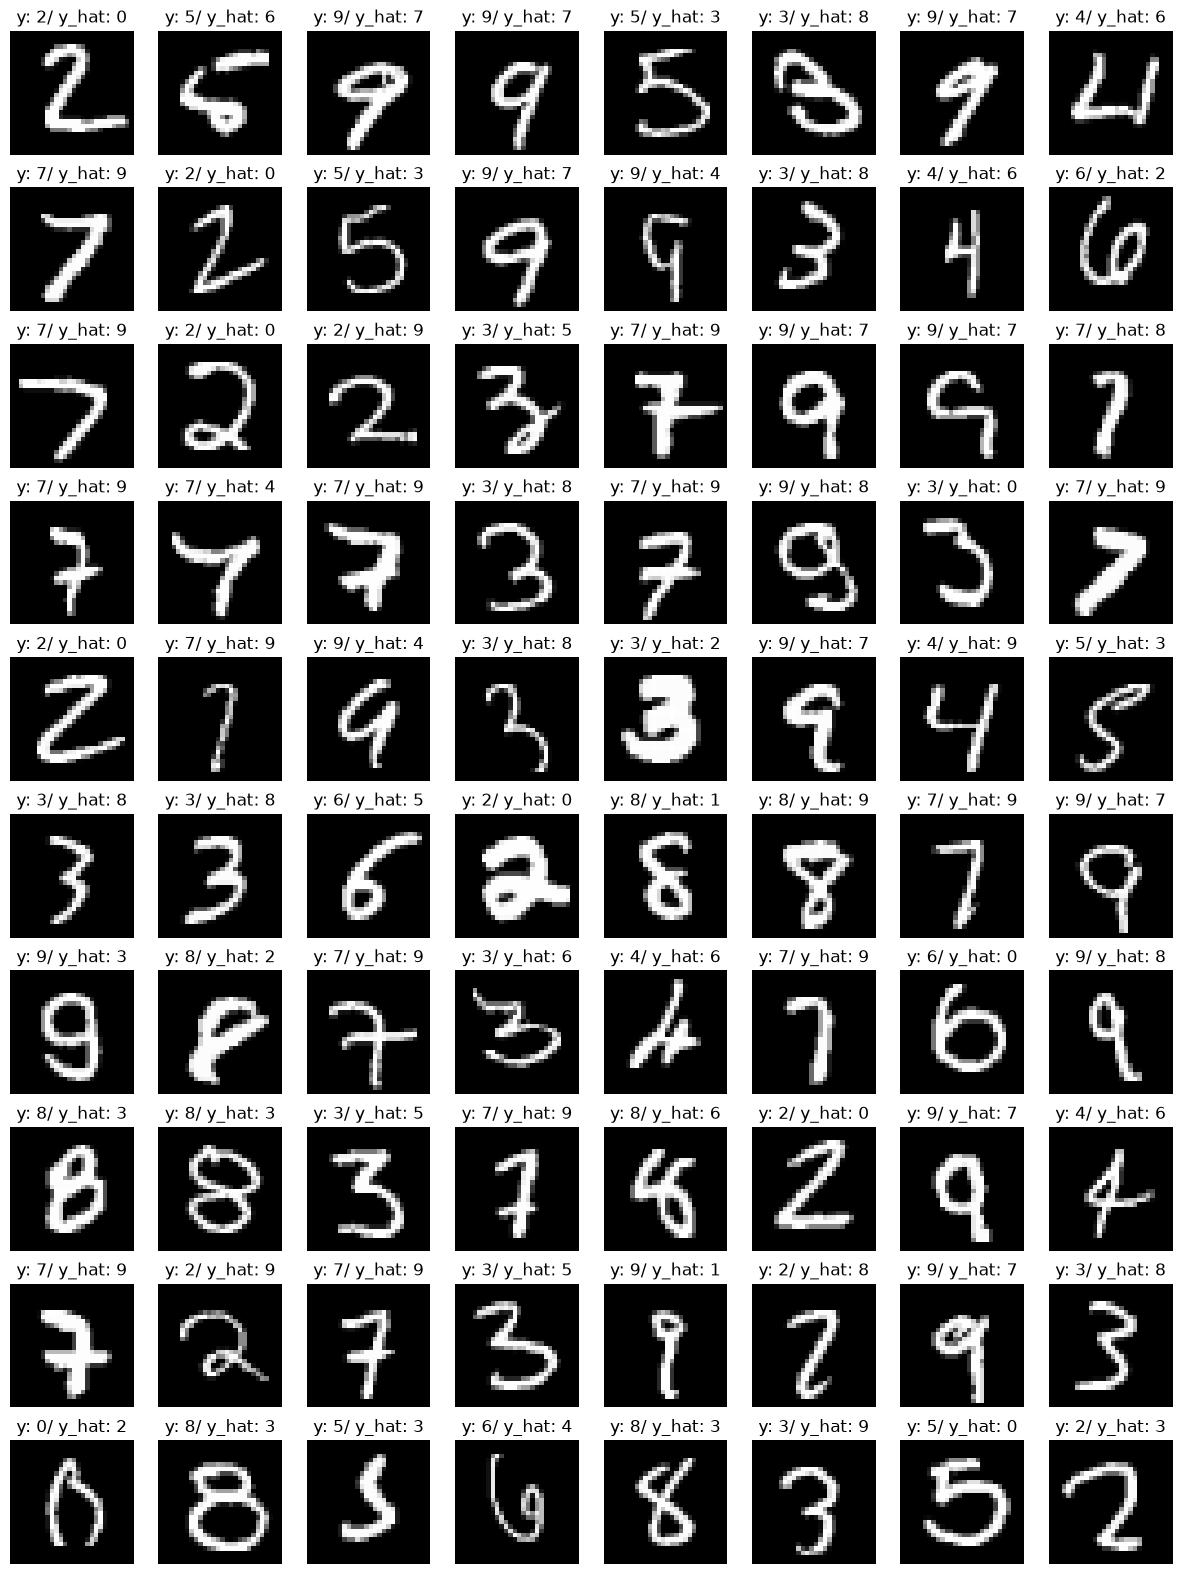

In [29]:
n_show = 80   # only plot the first 80 mistakes, the grid has 10 x 8 slots
fig = plt.figure(figsize=(15, 20))
z = 0
incorrect_list = []
for i in range(len(test_y)):
    y = test_y[i]
    y_hat = pred_test[i]
    if y != y_hat:
        incorrect_list.append(i)
        if z < n_show:
            z += 1
            ax = fig.add_subplot(10, 8, z)
            ax.imshow(test_X[i], cmap=plt.get_cmap('gray'))
            ax.set_title('y: {y}/ y_hat: {y_hat}'
                         .format(y=test_y[i], y_hat=pred_test[i]))
            plt.axis('off')

print("wrong predictions:", len(incorrect_list))

# Define function for getting derivative of loss with respect to input for saliency maps

In [30]:
def get_saliency_map(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    cost = compute_cost(probas, y)
    grads = L_model_backward(probas, y, caches)
    dy_dx = grads["dA0"]

    return np.argmax(probas, axis=0), dy_dx

# Prepare incorrectly predicted data for saliency maps 

In [31]:
saliency_test = test_x[:, incorrect_list]
saliency_test.reshape(saliency_test.shape[0],len(incorrect_list))
print(saliency_test.shape)

saliency_test_y = test_y[incorrect_list]
print(saliency_test_y.shape)

test_y_one_hot_for_saliency = to_categorical(saliency_test_y)
test_y_one_hot_for_saliency = np.einsum('vz->zv', test_y_one_hot_for_saliency)

(784, 2061)
(2061,)


# Get predictions and derivative of loss with respect to input

In [32]:
probas, dy_dx = get_saliency_map(saliency_test, test_y_one_hot_for_saliency, parameters)

# Reshape and normalize results for plot 

In [33]:
dy_dx_one_rs = dy_dx.reshape(28,28,dy_dx.shape[1])

normalized_tensor = np.multiply(
    255, (((dy_dx_one_rs - np.min(dy_dx_one_rs))
    / (np.max(dy_dx_one_rs) - np.min(dy_dx_one_rs)))))

# Apply penalty for smaller values

In [34]:
log = (1/(1+np.log((np.max(normalized_tensor) - normalized_tensor + 0.0001))))
normalized_tensor_weighted = np.multiply(normalized_tensor,log)

# The brightest points show the highest impact on loss

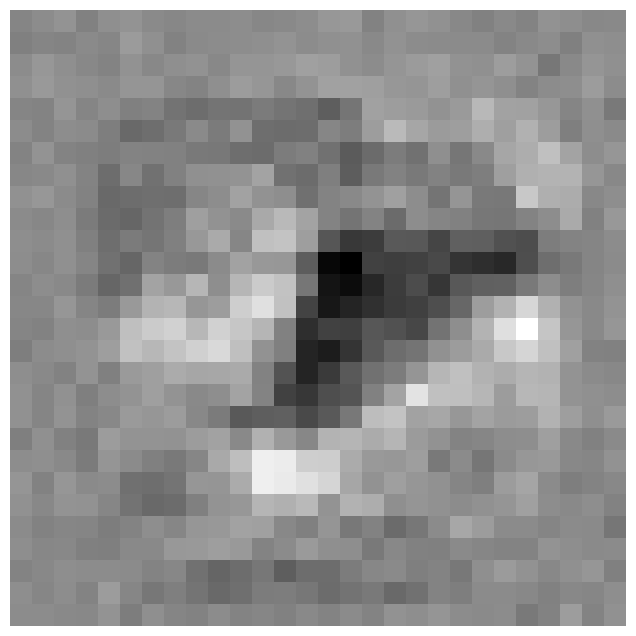

In [35]:
plt.figure(figsize=(8, 8))
plt.axis('off')
plt.imshow(normalized_tensor_weighted[:,:,1], cmap='gray')
plt.show()

# Darken the prediction images so saliency points become the brightest ones in image

In [36]:
saliency_test = test_x[:, incorrect_list]
saliency_test.reshape(saliency_test.shape[0],len(incorrect_list))
saliency_test = saliency_test.reshape(28,28,saliency_test.shape[1])
saliency_test = np.multiply(
    20, (saliency_test - np.min(saliency_test))
    / (np.max(saliency_test) - np.min(saliency_test))
)

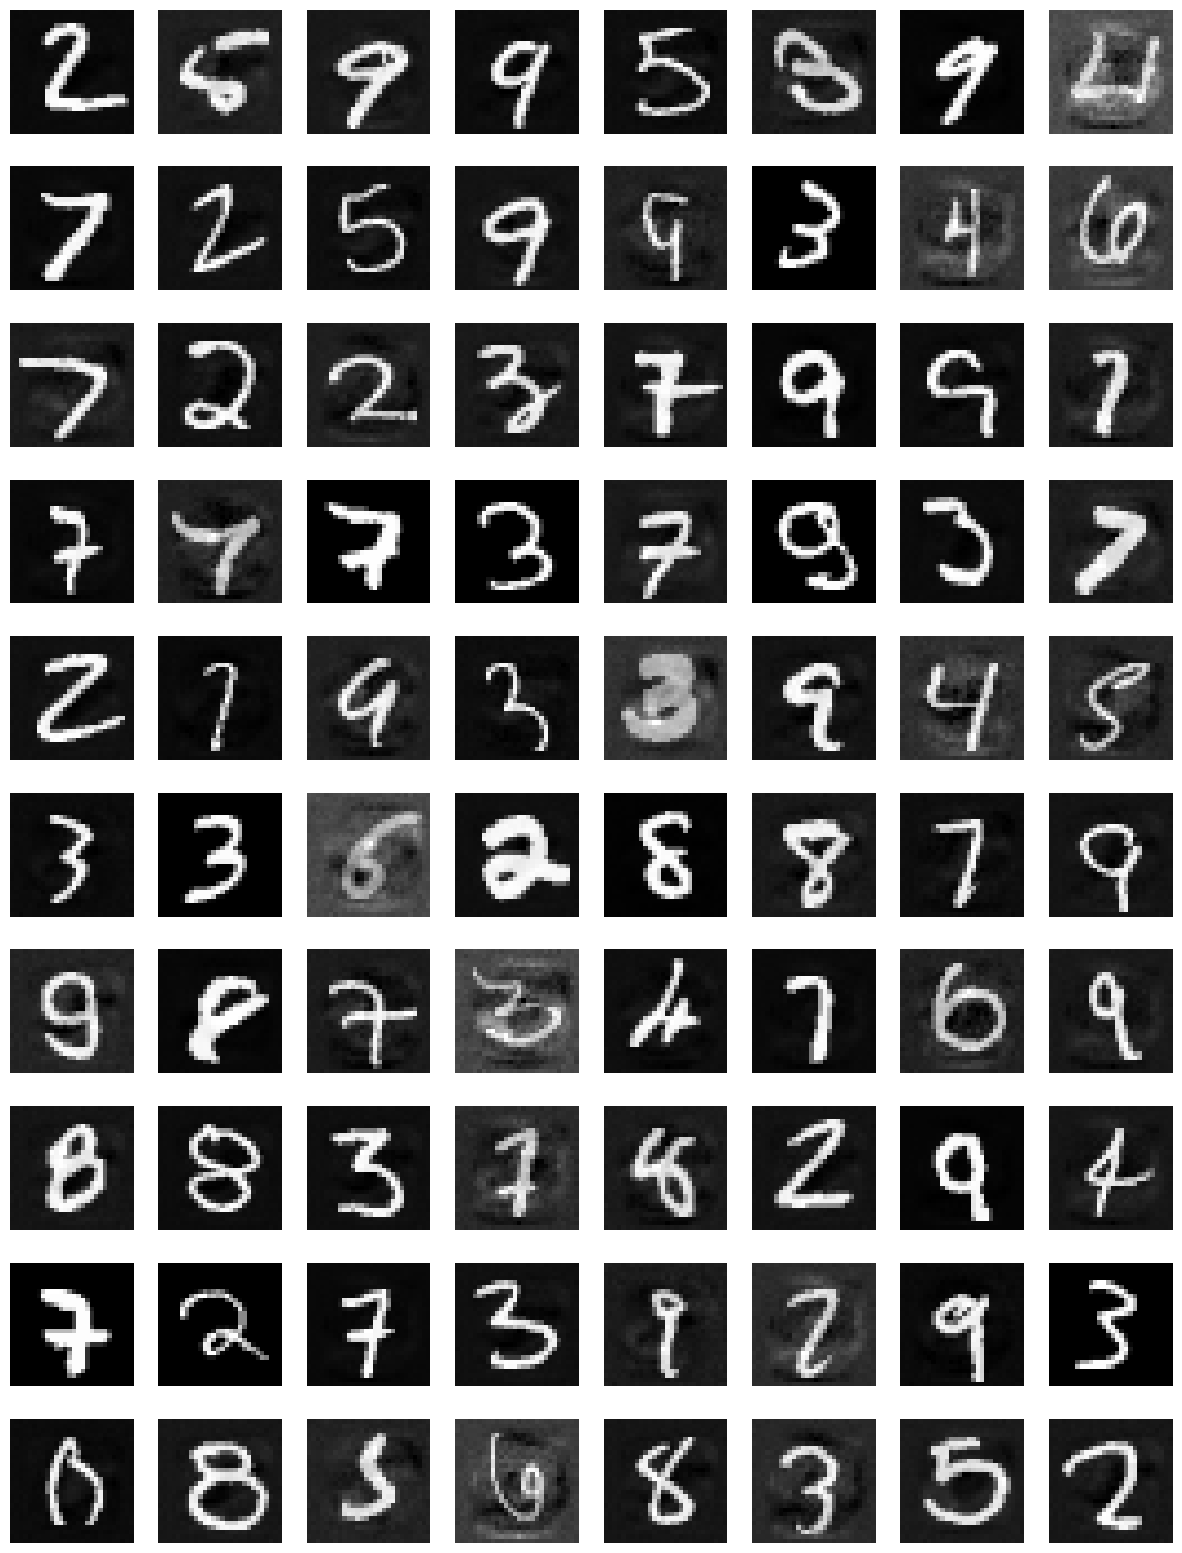

In [37]:
fig = plt.figure(figsize=(15, 20))
z = 0
for i in range(min(n_show, saliency_test.shape[2])):
    z += 1
    picture_i = saliency_test[:,:,i]
    saliency_map_i = normalized_tensor_weighted[:,:,i]
    ax = fig.add_subplot(10, 8, z)
    super_imposed = cv2.addWeighted(picture_i, 0.5, saliency_map_i, 0.5, 0.0, dtype=cv2.CV_64F)
    ax.imshow(super_imposed, cmap=plt.get_cmap('gray'))
    
    plt.axis('off')